# 名詞限定クラスタ：クラスタ0・4除外後の再正規化

2016〜2026年の名詞限定KMeans結果からクラスタ0・4を除外し、残る8クラスタの構成比を100%へ再正規化します。KMeansは再学習せず、既存のクラスタ番号と発言割当を維持します。

In [1]:
from pathlib import Path
import os

ROOT = Path.cwd()
if not (ROOT / 'analysis').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import seaborn as sns

INPUT_DIR = ROOT / 'analysis/clustering_2016_2026_nouns'
OUTPUT_DIR = ROOT / 'analysis/clustering_2016_2026_nouns_excluding_0_4_renormalized'
EXCLUDED_CLUSTERS = {0, 4}
CLUSTER_LABELS = {
    1: '感染症・公衆衛生',
    2: '政治・政党・政治資金',
    3: '経済・物価・賃金',
    5: '予算・財政運営',
    6: '調査・報告・検証',
    7: '社会保障・子育て支援',
    8: '防衛・安全保障',
    9: '外交・国際関係',
}
EXPECTED_INPUT_ROWS = 67882

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
print(f'Matplotlib font: {MAC_JAPANESE_FONT}')

Matplotlib font: Hiragino Sans


## 1. 入力と除外対象の検証

In [2]:
assignments = pd.read_csv(INPUT_DIR / 'speech_clusters.csv', encoding='utf-8-sig', parse_dates=['date'])
source_summary = pd.read_csv(INPUT_DIR / 'cluster_summary.csv', encoding='utf-8-sig')
assert len(assignments) == EXPECTED_INPUT_ROWS
assert assignments['speechID'].is_unique
assert set(assignments['cluster']) == set(range(10))
assert EXCLUDED_CLUSTERS <= set(assignments['cluster'])
excluded = assignments.loc[assignments['cluster'].isin(EXCLUDED_CLUSTERS)].copy()
retained = assignments.loc[~assignments['cluster'].isin(EXCLUDED_CLUSTERS)].copy().reset_index(drop=True)
excluded.loc[:, 'exclusion_reason'] = 'excluded_cluster_' + excluded['cluster'].astype(str)
assert len(retained) + len(excluded) == len(assignments)
assert set(retained['speechID']).isdisjoint(set(excluded['speechID']))
assert set(retained['cluster']) == set(range(10)) - EXCLUDED_CLUSTERS
display(pd.Series({
    '入力発言': len(assignments),
    'クラスタ0除外': int(assignments['cluster'].eq(0).sum()),
    'クラスタ4除外': int(assignments['cluster'].eq(4).sum()),
    '除外合計': len(excluded),
    '残存発言': len(retained),
    '残存クラスタ数': retained['cluster'].nunique(),
}).to_frame('value'))

,value
入力発言,67882
クラスタ0除外,23454
クラスタ4除外,8286
除外合計,31740
残存発言,36142
残存クラスタ数,8


## 2. 残る8クラスタを100%へ再正規化

,cluster,cluster_label,count,ratio,top_terms
0,1,感染症・公衆衛生,4036,11.17%,感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症
1,2,政治・政党・政治資金,6268,17.34%,議論 | 政治 | 自民党 | 議員 | 国民 | 資金 | 政治 資金 | 政党 | 選挙 | 総裁 | 政策 | 団体
2,3,経済・物価・賃金,4430,12.26%,経済 | 賃金 | 政策 | 成長 | 物価 | 賃上げ | 企業 | 財政 | 投資 | 金融 | 金利 | 日本
3,5,予算・財政運営,3705,10.25%,予算 | 年度 | 補正 | 補正 予算 | 令和 | 令和 年度 | 計上 | 予算 委員会 | 基金 | 委員会 | 審議 | 対策
4,6,調査・報告・検証,3076,8.51%,調査 | 結果 | 調査 結果 | 委員会 | 報告 | 統計 | 調査 調査 | 事案 | データ | 公表 | 先程 | 第三者
5,7,社会保障・子育て支援,6018,16.65%,負担 | 制度 | 子供 | 財源 | 子育て | 軽減 | 社会保障 | 支援 | 給付 | 教育 | 無償化 | 消費税
6,8,防衛・安全保障,3523,9.75%,安全 | 安全 保障 | 保障 | 自衛隊 | 防衛 | 我が国 | 攻撃 | 米軍 | 基地 | ミサイル | 能力 | 日米
7,9,外交・国際関係,5086,14.07%,日本 | アメリカ | 世界 | 会談 | 交渉 | 我が国 | 日米 | 首脳 | 国際 | 中国 | 米国 | トランプ大統領


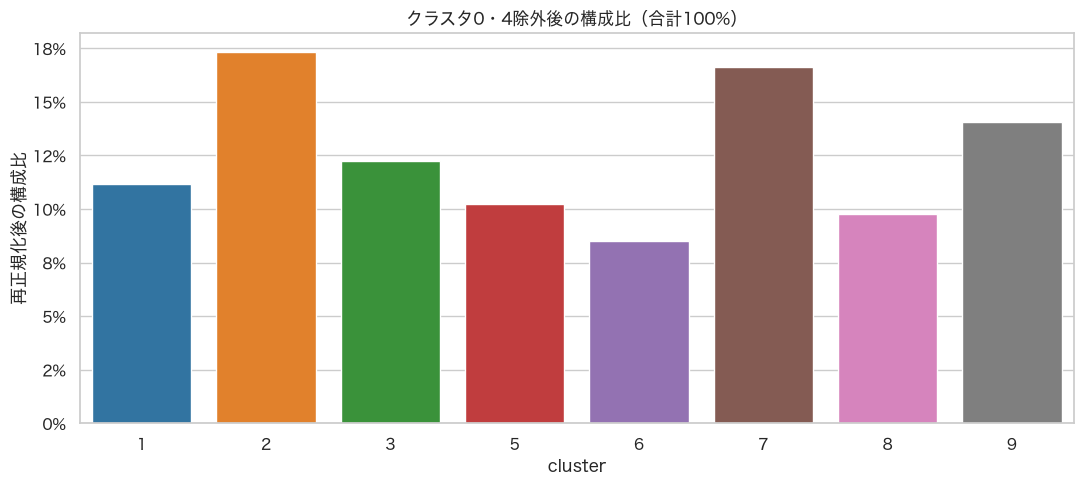

In [3]:
summary_columns = ['cluster', 'provisional_label', 'top_terms', 'representative_speech_ids', 'cluster_label']
cluster_counts = retained.groupby('cluster', as_index=False).agg(count=('speechID', 'size'))
summary = (
    source_summary.loc[~source_summary['cluster'].isin(EXCLUDED_CLUSTERS), summary_columns]
    .merge(cluster_counts, on='cluster', how='inner', validate='1:1')
    .assign(ratio=lambda d: d['count'] / d['count'].sum())
    .sort_values('cluster')
    .reset_index(drop=True)
)
assert set(CLUSTER_LABELS) == set(summary['cluster'])
summary.loc[:, 'cluster_label'] = summary['cluster'].map(CLUSTER_LABELS)
retained.loc[:, 'cluster_label'] = retained['cluster'].map(CLUSTER_LABELS)
retained = retained.merge(summary[['cluster', 'ratio']].rename(columns={'ratio': 'renormalized_cluster_ratio'}), on='cluster', how='left', validate='m:1')
assert abs(summary['ratio'].sum() - 1.0) < 1e-12
assert summary['count'].sum() == len(retained)
assert retained['renormalized_cluster_ratio'].notna().all()
display(summary[['cluster', 'cluster_label', 'count', 'ratio', 'top_terms']].style.format({'ratio': '{:.2%}'}))
plt.figure(figsize=(11, 5))
sns.barplot(data=summary, x='cluster', y='ratio', hue='cluster', palette='tab10', legend=False)
plt.gca().yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
plt.title('クラスタ0・4除外後の構成比（合計100%）')
plt.ylabel('再正規化後の構成比')
plt.tight_layout();

## 3. 年別構成比を各年100%へ再正規化

cluster,1,2,3,5,6,7,8,9
year,,,,,,,,
2016,1.2%,20.3%,22.0%,7.1%,6.5%,19.9%,10.1%,12.9%
2017,0.9%,14.5%,7.7%,8.4%,19.4%,12.5%,15.3%,21.2%
2018,1.6%,14.0%,9.5%,8.9%,18.7%,13.8%,14.6%,18.9%
2019,2.8%,10.6%,16.2%,5.8%,20.3%,14.4%,11.9%,18.0%
2020,39.1%,14.0%,7.3%,8.5%,4.3%,9.8%,5.4%,11.5%
2021,39.2%,8.5%,6.0%,7.0%,13.4%,9.1%,6.2%,10.6%
2022,23.7%,12.4%,15.8%,9.4%,5.1%,12.8%,10.1%,10.8%
2023,3.1%,18.8%,14.2%,10.0%,3.0%,24.1%,13.6%,13.1%
2024,1.0%,44.6%,8.9%,7.0%,5.9%,17.4%,7.0%,8.3%


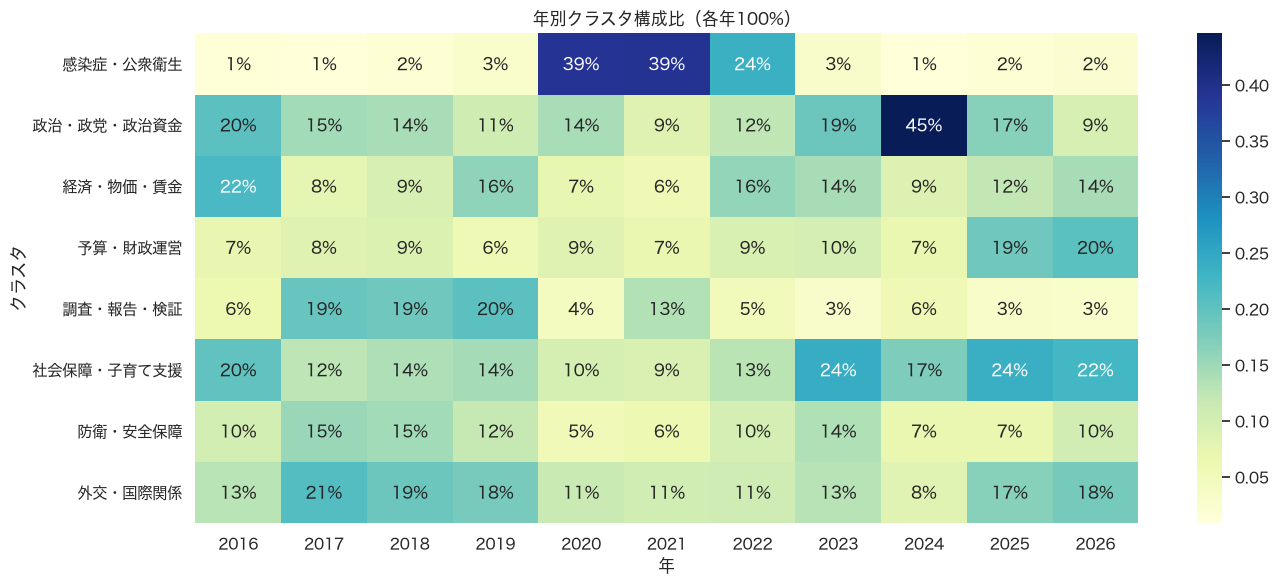

In [4]:
yearly_counts = pd.crosstab(retained['year'], retained['cluster'])
yearly_ratios = yearly_counts.div(yearly_counts.sum(axis=1), axis=0)
assert yearly_ratios.sum(axis=1).sub(1.0).abs().max() < 1e-12
display(yearly_ratios.style.format('{:.1%}'))
yearly_plot = yearly_ratios.T.rename(index=CLUSTER_LABELS)
plt.figure(figsize=(14, 6))
sns.heatmap(yearly_plot, cmap='YlGnBu', annot=True, fmt='.0%')
plt.title('年別クラスタ構成比（各年100%）')
plt.xlabel('年')
plt.ylabel('クラスタ')
plt.tight_layout();

## 4. CSV出力と最終検証

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
retained.to_csv(OUTPUT_DIR / 'speech_clusters_excluding_0_4.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
summary.to_csv(OUTPUT_DIR / 'cluster_summary_renormalized.csv', index=False, encoding='utf-8-sig')
excluded.to_csv(OUTPUT_DIR / 'excluded_clusters_0_4.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
yearly_counts.to_csv(OUTPUT_DIR / 'yearly_cluster_counts.csv', encoding='utf-8-sig')
yearly_ratios.to_csv(OUTPUT_DIR / 'yearly_cluster_ratios_renormalized.csv', encoding='utf-8-sig')
saved = pd.read_csv(OUTPUT_DIR / 'speech_clusters_excluding_0_4.csv', encoding='utf-8-sig')
saved_summary = pd.read_csv(OUTPUT_DIR / 'cluster_summary_renormalized.csv', encoding='utf-8-sig')
assert len(saved) == len(retained)
assert set(saved['cluster']) == set(range(10)) - EXCLUDED_CLUSTERS
assert saved.set_index('cluster')['cluster_label'].to_dict().keys() == CLUSTER_LABELS.keys()
assert saved.groupby('cluster')['cluster_label'].first().to_dict() == CLUSTER_LABELS
assert abs(saved_summary['ratio'].sum() - 1.0) < 1e-9
assert saved_summary.set_index('cluster')['cluster_label'].to_dict() == CLUSTER_LABELS
print(f'出力先: {OUTPUT_DIR}')
print(f'検証完了: 入力{len(assignments):,}件、除外{len(excluded):,}件、残存{len(retained):,}件、構成比合計{summary["ratio"].sum():.1%}')

出力先: /Users/tasskkiu2/kokkai/analysis/clustering_2016_2026_nouns_excluding_0_4_renormalized
検証完了: 入力67,882件、除外31,740件、残存36,142件、構成比合計100.0%
